# Física II — Movimento Harmônico Simples

### Material de estudo visual — Engenharia Naval, Poli-USP

Este notebook é um guia de **revisão visual** para a Parte I do curso de Física II: Movimento Harmônico Simples (MHS). Não é uma lista de exercícios — é um "livro vivo": cada fórmula importante vem acompanhada de um gráfico, uma animação ou um diagrama que mostra o que ela significa fisicamente.

Rode as células em ordem (a primeira configura o ambiente). Sinta-se livre para mudar os parâmetros (massas, constantes elásticas, amplitudes, ângulos) e observar como gráficos e animações mudam — essa é a melhor forma de construir intuição.

## Sumário

1. [Movimentos periódicos](#sec1)
2. [Sistema massa-mola e a lei de Hooke](#sec2)
3. [Energia potencial associada a uma força restauradora](#sec3)
4. [MHS como limite de pequenas oscilações](#sec4)
5. [Equação diferencial do MHS e EDOs de 2ª ordem homogêneas](#sec5)
6. [Solução da equação diferencial do MHS](#sec6)
7. [Energia no MHS](#sec7)
8. [Aplicações no limite de pequenas oscilações](#sec8)
    - [8.1 Pêndulo de torção](#sec8-1)
    - [8.2 Pêndulo simples](#sec8-2)
    - [8.3 Pêndulo físico](#sec8-3)
9. [Oscilações de duas partículas](#sec9)
10. [MHS como projeção de um MCU](#sec10)
11. [Notação complexa para o MHS (fórmula de Euler)](#sec11)


## Configuração inicial

Rode esta célula primeiro. Ela importa tudo que vamos usar e define um estilo visual consistente (grid leve, paleta de cores agradável) para todos os gráficos do notebook. Como não temos `scipy`, qualquer integração numérica será feita "na mão" (Euler-Cromer / RK4) usando apenas `numpy`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch, Circle, Arc, Rectangle
from IPython.display import HTML
import sympy as sp

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "lines.linewidth": 2.2,
    "axes.prop_cycle": plt.cycler(color=[
        "#1f77b4", "#d62728", "#2ca02c", "#9467bd",
        "#ff7f0e", "#17becf", "#8c564b", "#e377c2",
    ]),
})

COR_DESTAQUE = "#d62728"
COR_OK = "#2ca02c"
COR_AZUL = "#1f77b4"
COR_ROXO = "#9467bd"
COR_LARANJA = "#ff7f0e"
print("Setup concluído: numpy, matplotlib, sympy prontos para uso.")


Setup concluído: numpy, matplotlib, sympy prontos para uso.


<a id="sec1"></a>
## 1. Movimentos periódicos

Um movimento é **periódico** quando se repete identicamente em intervalos de tempo iguais. Chamamos esse intervalo de **período** $T$ (em segundos). A **frequência** $f$ é o número de repetições por unidade de tempo:

$$f = \frac{1}{T} \quad \text{(unidade: Hz = 1/s)}$$

Em vez de contar "voltas por segundo", é frequentemente mais conveniente usar a **frequência angular**

$$\omega = 2\pi f = \frac{2\pi}{T} \quad \text{(rad/s)}$$

que mede o "ângulo equivalente" percorrido por unidade de tempo — útil porque funções como $\cos(\omega t)$ têm período natural $2\pi$ em seu argumento.

Nem todo movimento periódico é harmônico: uma onda quadrada e um dente de serra também se repetem no tempo, mas não são senoides. O MHS é o caso particular (e mais importante) em que o movimento é descrito por um seno ou cosseno puro.

> **Intuição física:** pense em $T$ como "quanto tempo dura uma volta completa" e em $f$ como "quantas voltas cabem em 1 segundo". $\omega$ é só uma forma mais conveniente (em rad/s) de medir a mesma coisa.

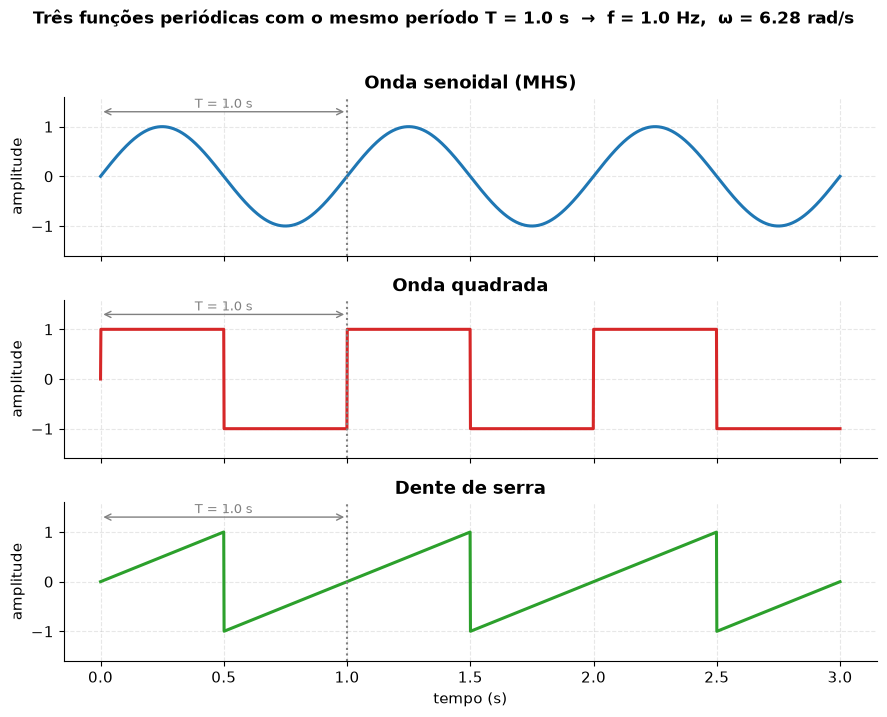

In [2]:
t = np.linspace(0, 3, 2000)
T = 1.0  # período em segundos
f = 1 / T
omega = 2 * np.pi * f

seno = np.sin(2 * np.pi * f * t)
quadrada = np.sign(np.sin(2 * np.pi * f * t))
dente_de_serra = 2 * (t / T - np.floor(0.5 + t / T))

fig, axs = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
sinais = [(seno, "Onda senoidal (MHS)", COR_AZUL),
          (quadrada, "Onda quadrada", COR_DESTAQUE),
          (dente_de_serra, "Dente de serra", COR_OK)]

for ax, (sinal, titulo, cor) in zip(axs, sinais):
    ax.plot(t, sinal, color=cor)
    ax.set_title(titulo)
    ax.set_ylabel("amplitude")
    ax.axvline(T, color="gray", linestyle=":", linewidth=1.5)
    ax.annotate("", xy=(T, 1.3), xytext=(0, 1.3),
                arrowprops=dict(arrowstyle="<->", color="gray"))
    ax.text(T / 2, 1.38, f"T = {T:.1f} s", ha="center", fontsize=9, color="gray")
    ax.set_ylim(-1.6, 1.6)

axs[-1].set_xlabel("tempo (s)")
fig.suptitle(f"Três funções periódicas com o mesmo período T = {T} s  →  f = {f:.1f} Hz,  ω = {omega:.2f} rad/s",
             y=1.02, fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()


<a id="sec2"></a>
## 2. Sistema massa-mola segundo a lei de Hooke

A **Lei de Hooke** diz que uma mola ideal exerce uma força restauradora proporcional ao deslocamento $x$ em relação à posição de equilíbrio, e sempre **oposta** a esse deslocamento:

$$F(x) = -kx$$

onde $k$ é a constante elástica da mola (N/m). O sinal negativo é a essência física do MHS: a força sempre "puxa de volta" para o equilíbrio, nunca empurra para longe dele — por isso dizemos que é uma **força restauradora**.

> **Dica de prova:** sempre que você vir $F=-kx$ (ou qualquer força proporcional e oposta ao deslocamento), pode esperar um MHS com $\omega=\sqrt{k/m}$ sem precisar resolver a EDO do zero.

In [3]:
def massa_mola_frame(ax, x, k=1.0, A=1.0):
    ax.clear()
    parede_x = -1.6
    ax.add_patch(Rectangle((parede_x - 0.08, -0.35), 0.08, 0.7, color="dimgray"))

    n_coils = 14
    xs_mola = np.linspace(parede_x, x, n_coils * 2)
    ys_mola = 0.15 * np.sign(np.sin(np.linspace(0, n_coils * np.pi, n_coils * 2)))
    ys_mola[0] = 0
    ys_mola[-1] = 0
    ax.plot(xs_mola, ys_mola, color="dimgray", linewidth=1.8)

    bloco = Rectangle((x - 0.2, -0.2), 0.4, 0.4, color=COR_AZUL, zorder=5)
    ax.add_patch(bloco)

    F = -k * x
    if abs(F) > 1e-3:
        seta_cor = COR_DESTAQUE if F < 0 else COR_OK
        comp = np.clip(F, -1.2, 1.2)
        ax.annotate("", xy=(x + 0.2 + comp, 0), xytext=(x + 0.2, 0),
                    arrowprops=dict(arrowstyle="-|>", color=seta_cor, linewidth=2.5))
        ax.text(x + 0.2 + comp / 2, 0.3, f"F = {F:+.2f} N", color=seta_cor,
                ha="center", fontsize=9, fontweight="bold")

    ax.axvline(0, color="gray", linestyle=":", linewidth=1)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-0.8, 0.8)
    ax.set_yticks([])
    ax.set_xlabel("posição x (m)")
    ax.set_title(f"Massa-mola (k = {k:.1f} N/m): a força sempre aponta para x = 0")


k_demo = 2.0
A_demo = 1.3
omega_demo = np.sqrt(k_demo)  # massa unitária
fig, ax = plt.subplots(figsize=(8, 3.5))
frames = np.linspace(0, 2 * np.pi / omega_demo, 60)


def animar(i):
    x_i = A_demo * np.cos(omega_demo * frames[i])
    massa_mola_frame(ax, x_i, k=k_demo, A=A_demo)
    return []


anim = animation.FuncAnimation(fig, animar, frames=len(frames), interval=50, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())


<a id="sec3"></a>
## 3. Energia potencial associada a uma força restauradora

Toda força restauradora conservativa $F(x)=-kx$ vem de uma energia potencial

$$U(x) = \frac{1}{2}kx^2, \qquad \text{pois } F = -\frac{dU}{dx}$$

Esse é o **poço de potencial harmônico**: uma parábola com mínimo em $x=0$. A energia mecânica total $E = K + U$ é conservada; conforme a massa oscila, ela troca energia cinética por potencial e vice-versa, mas a soma permanece constante — é exatamente a mesma ideia do poço de potencial que vimos em Física I, agora aplicada ao MHS.

> **Intuição física:** imagine uma bolinha de gude dentro de uma tigela parabólica. Ela ganha velocidade (K aumenta) ao descer em direção ao fundo e perde velocidade (U aumenta) ao subir pelas bordas — a altura total da "energia" nunca muda.

In [4]:
k_e = 2.0
m_e = 1.0
A_e = 1.5
omega_e = np.sqrt(k_e / m_e)
E_total = 0.5 * k_e * A_e**2

x_parab = np.linspace(-1.8, 1.8, 400)
U_parab = 0.5 * k_e * x_parab**2

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axs[0]
ax.plot(x_parab, U_parab, color=COR_AZUL, linewidth=2.5)
ax.axhline(E_total, color="gray", linestyle=":", label=f"E = {E_total:.2f} J (constante)")
bolinha, = ax.plot([], [], "o", color=COR_DESTAQUE, markersize=14, zorder=5)
ax.set_xlabel("x (m)")
ax.set_ylabel("Energia (J)")
ax.set_title("Poço de potencial harmônico U(x) = ½kx²")
ax.legend(loc="upper center")
ax.set_ylim(-0.3, E_total * 1.3)

ax2 = axs[1]
barra_K = ax2.bar(["K", "U"], [0, 0], color=[COR_OK, COR_LARANJA])
ax2.set_ylim(0, E_total * 1.15)
ax2.axhline(E_total, color="gray", linestyle=":", label="E total")
ax2.set_ylabel("Energia (J)")
ax2.set_title("K e U trocam, E permanece")
ax2.legend(loc="upper right")

fig.tight_layout()

frames_e = np.linspace(0, 2 * np.pi / omega_e, 80)


def animar_energia(i):
    t_i = frames_e[i]
    x_i = A_e * np.cos(omega_e * t_i)
    v_i = -A_e * omega_e * np.sin(omega_e * t_i)
    U_i = 0.5 * k_e * x_i**2
    K_i = 0.5 * m_e * v_i**2
    bolinha.set_data([x_i], [U_i])
    for rect, val in zip(barra_K, [K_i, U_i]):
        rect.set_height(val)
    return [bolinha, *barra_K]


anim2 = animation.FuncAnimation(fig, animar_energia, frames=len(frames_e), interval=50, blit=False)
plt.close(fig)
HTML(anim2.to_jshtml())


<a id="sec4"></a>
## 4. MHS como limite de pequenas oscilações

Por que o MHS aparece em tantos sistemas físicos diferentes (pêndulos, moléculas, circuitos)? Porque **qualquer** potencial suave $U(x)$ perto de um mínimo local $x_0$ pode ser aproximado por uma parábola, via série de Taylor:

$$U(x) \approx U(x_0) + \underbrace{U'(x_0)}_{=\,0}(x-x_0) + \frac{1}{2}U''(x_0)(x-x_0)^2 + \cdots$$

Como $x_0$ é mínimo, $U'(x_0)=0$, e o termo dominante é quadrático — exatamente a forma do potencial harmônico, com "$k$ efetivo" dado por $k_{\text{ef}} = U''(x_0)$. Essa é a razão profunda pela qual o MHS é universal: **toda oscilação de pequena amplitude em torno de um equilíbrio estável é aproximadamente harmônica.**

> **Dica de prova:** quando o enunciado disser "para pequenas oscilações" ou "próximo ao equilíbrio", é sinal verde para aplicar $\omega^2 = U''(x_0)/m$ mesmo que a força original não seja $-kx$.

U(x) = x**4 - x**2
U'(x) = 4*x**3 - 2*x
Mínimo em x0 = 0.7071067811865476
k_efetivo = U''(x0) = 4.000000000000002


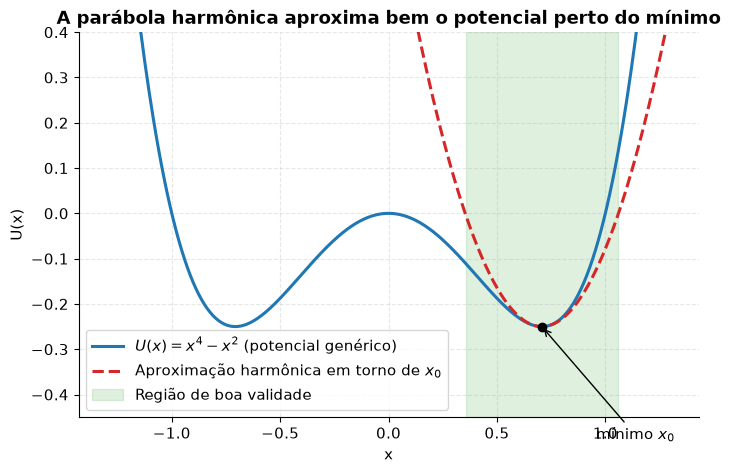

In [5]:
x_sym = sp.symbols('x')
U_sym = x_sym**4 - x_sym**2  # potencial genérico tipo poço duplo (um dos mínimos)

Up = sp.diff(U_sym, x_sym)
Upp = sp.diff(U_sym, x_sym, 2)

x0_candidates = sp.solve(sp.Eq(Up, 0), x_sym)
x0 = [float(r) for r in x0_candidates if r > 0][0]
k_ef = float(Upp.subs(x_sym, x0))

print("U(x) =", U_sym)
print("U'(x) =", Up)
print("Mínimo em x0 =", x0)
print("k_efetivo = U''(x0) =", k_ef)

f_num = sp.lambdify(x_sym, U_sym, "numpy")
xs = np.linspace(-1.3, 1.3, 400)
U_vals = f_num(xs)
U_parab_aprox = f_num(x0) + 0.5 * k_ef * (xs - x0) ** 2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs, U_vals, color=COR_AZUL, label=r"$U(x) = x^4 - x^2$ (potencial genérico)")
ax.plot(xs, U_parab_aprox, color=COR_DESTAQUE, linestyle="--",
        label="Aproximação harmônica em torno de $x_0$")
ax.axvspan(x0 - 0.35, x0 + 0.35, color=COR_OK, alpha=0.15, label="Região de boa validade")
ax.plot(x0, f_num(x0), "o", color="black", zorder=5)
ax.annotate("mínimo $x_0$", xy=(x0, f_num(x0)), xytext=(x0 + 0.25, f_num(x0) - 0.25),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("x")
ax.set_ylabel("U(x)")
ax.set_title("A parábola harmônica aproxima bem o potencial perto do mínimo")
ax.legend()
ax.set_ylim(min(U_vals) - 0.2, 0.4)
plt.show()


<a id="sec5"></a>
## 5. Equação diferencial do MHS e EDOs de 2ª ordem homogêneas

Pela 2ª Lei de Newton aplicada ao sistema massa-mola:

$$F = ma \;\Longrightarrow\; -kx = m\ddot x \;\Longrightarrow\; \ddot x + \omega^2 x = 0, \qquad \omega^2 \equiv \frac{k}{m}$$

Essa é uma **equação diferencial ordinária (EDO) linear de 2ª ordem, homogênea, com coeficientes constantes**. A receita geral para resolver esse tipo de equação é propor uma solução exponencial $x(t)=e^{\lambda t}$, o que leva à **equação característica**:

$$\lambda^2 + \omega^2 = 0 \;\Longrightarrow\; \lambda = \pm i\omega$$

Raízes complexas puras ($\lambda = \pm i\omega$) sempre geram soluções oscilatórias reais do tipo $\cos(\omega t)$ e $\sin(\omega t)$ — é exatamente isso que diferencia o MHS de, por exemplo, um decaimento exponencial (que teria raízes reais).

> **Intuição física:** a equação característica "resume" toda a física do problema em dois números (as raízes $\lambda$). Raízes imaginárias puras = oscilação sem crescimento nem decaimento, porque não há dissipação de energia no MHS ideal.

In [6]:
t_sym = sp.symbols('t')
x_f = sp.Function('x')
omega_sym = sp.symbols('omega', positive=True)

edo = sp.Eq(sp.diff(x_f(t_sym), t_sym, 2) + omega_sym**2 * x_f(t_sym), 0)
solucao = sp.dsolve(edo, x_f(t_sym))

print("EDO do MHS:")
sp.pprint(edo)
print("\nSolução geral (via sympy.dsolve):")
sp.pprint(solucao)


EDO do MHS:


           2           
 2        d            
ω ⋅x(t) + ───(x(t)) = 0
            2          
          dt           

Solução geral (via sympy.dsolve):
x(t) = C₁⋅sin(ω⋅t) + C₂⋅cos(ω⋅t)


<a id="sec6"></a>
## 6. Solução da equação diferencial do MHS

A solução geral pode ser escrita de forma equivalente como

$$x(t) = A\cos(\omega t + \phi)$$

onde $A$ é a **amplitude** (deslocamento máximo) e $\phi$ a **fase inicial**. As condições iniciais $x(0)=x_0$ e $\dot x(0)=v_0$ fixam $A$ e $\phi$:

$$A = \sqrt{x_0^2 + \left(\frac{v_0}{\omega}\right)^2}, \qquad \tan\phi = -\frac{v_0}{\omega x_0}$$

Vamos visualizar como $A$ e $\phi$ aparecem diretamente no gráfico de $x(t)$, e depois animar a massa oscilando em sincronia com a curva sendo traçada.

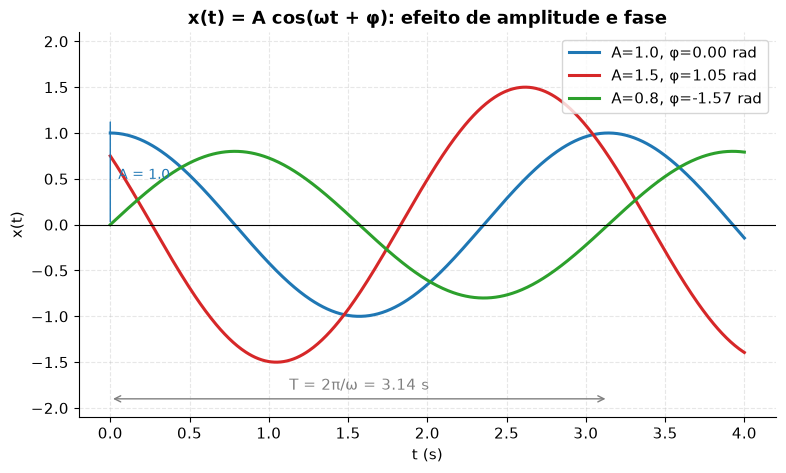

In [7]:
omega6 = 2.0
casos = [(1.0, 0.0, COR_AZUL), (1.5, np.pi / 3, COR_DESTAQUE), (0.8, -np.pi / 2, COR_OK)]
t6 = np.linspace(0, 4, 600)

fig, ax = plt.subplots(figsize=(9, 5))
for A, phi, cor in casos:
    x6 = A * np.cos(omega6 * t6 + phi)
    ax.plot(t6, x6, color=cor, label=f"A={A}, φ={phi:.2f} rad")

A0, phi0, cor0 = casos[0]
T6 = 2 * np.pi / omega6
ax.annotate("", xy=(0, A0 + 0.15), xytext=(0, 0), arrowprops=dict(arrowstyle="-", color=cor0))
ax.annotate(f"A = {A0}", xy=(0.05, A0 / 2), color=cor0, fontsize=10)
ax.annotate("", xy=(T6, -1.9), xytext=(0, -1.9), arrowprops=dict(arrowstyle="<->", color="gray"))
ax.text(T6 / 2, -1.8, f"T = 2π/ω = {T6:.2f} s", ha="center", color="gray")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("t (s)")
ax.set_ylabel("x(t)")
ax.set_title("x(t) = A cos(ωt + φ): efeito de amplitude e fase")
ax.legend(loc="upper right")
ax.set_ylim(-2.1, 2.1)
plt.show()


In [8]:
A6, phi6 = 1.3, 0.4
t_anim = np.linspace(0, 2 * T6, 160)
x_anim = A6 * np.cos(omega6 * t_anim + phi6)

fig, (ax_mola, ax_xt) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})

ax_xt.plot(t_anim, x_anim, color="lightgray", linewidth=1.5)
linha_tracada, = ax_xt.plot([], [], color=COR_AZUL, linewidth=2.5)
ponto_xt, = ax_xt.plot([], [], "o", color=COR_DESTAQUE, markersize=8)
ax_xt.set_xlim(t_anim[0], t_anim[-1])
ax_xt.set_ylim(-1.6, 1.6)
ax_xt.set_xlabel("t (s)")
ax_xt.set_ylabel("x(t)")
ax_xt.set_title("x(t) sendo traçado")

ax_mola.set_xlim(-2, 2)
ax_mola.set_ylim(-0.8, 0.8)
ax_mola.set_yticks([])
ax_mola.set_title("Oscilador massa-mola")


def animar_sinc(i):
    massa_mola_frame(ax_mola, x_anim[i], k=k_demo, A=A6)
    linha_tracada.set_data(t_anim[: i + 1], x_anim[: i + 1])
    ponto_xt.set_data([t_anim[i]], [x_anim[i]])
    return [linha_tracada, ponto_xt]


anim3 = animation.FuncAnimation(fig, animar_sinc, frames=len(t_anim), interval=40, blit=False)
plt.close(fig)
HTML(anim3.to_jshtml())


<a id="sec7"></a>
## 7. Energia no MHS

Com $x(t) = A\cos(\omega t + \phi)$ e $v(t) = -A\omega\sin(\omega t+\phi)$:

$$K(t) = \frac{1}{2}mv^2 = \frac{1}{2}m\omega^2A^2\sin^2(\omega t+\phi), \qquad U(t) = \frac{1}{2}kx^2 = \frac{1}{2}kA^2\cos^2(\omega t+\phi)$$

Como $k = m\omega^2$, a soma é constante:

$$E = K(t) + U(t) = \frac{1}{2}kA^2 \quad \text{(não depende de } t\text{)}$$

Note que $K$ e $U$ oscilam **defasados em $\pi/2$** (um é $\sin^2$, outro $\cos^2$): quando um é máximo, o outro é exatamente zero.

> **Dica de prova:** $K_{\max} = U_{\max} = E$. Isso é extremamente útil para achar a velocidade máxima rapidamente: $\frac12 m v_{\max}^2 = \frac12 kA^2 \Rightarrow v_{\max} = A\omega$.

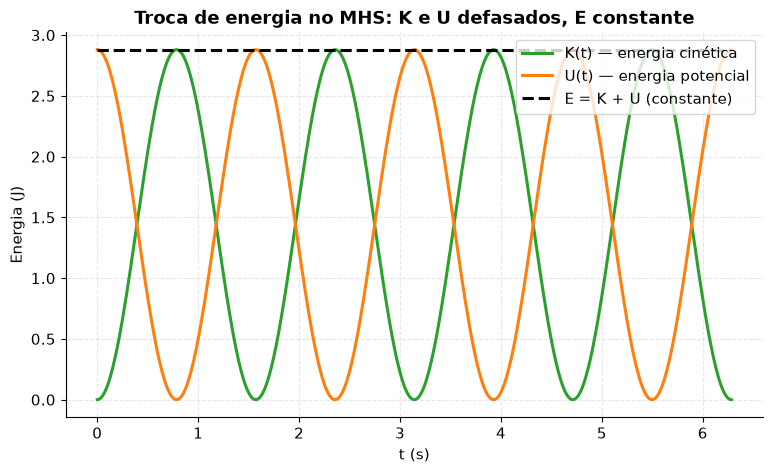

In [9]:
m7, k7, A7 = 1.0, 4.0, 1.2
omega7 = np.sqrt(k7 / m7)
t7 = np.linspace(0, 2 * 2 * np.pi / omega7, 500)
x7 = A7 * np.cos(omega7 * t7)
v7 = -A7 * omega7 * np.sin(omega7 * t7)
K7 = 0.5 * m7 * v7**2
U7 = 0.5 * k7 * x7**2
E7 = K7 + U7

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t7, K7, color=COR_OK, label="K(t) — energia cinética")
ax.plot(t7, U7, color=COR_LARANJA, label="U(t) — energia potencial")
ax.plot(t7, E7, color="black", linestyle="--", label="E = K + U (constante)")
ax.set_xlabel("t (s)")
ax.set_ylabel("Energia (J)")
ax.set_title("Troca de energia no MHS: K e U defasados, E constante")
ax.legend(loc="upper right")
plt.show()


<a id="sec8"></a>
## 8. Aplicações no limite de pequenas oscilações

<a id="sec8-1"></a>
### 8.1 Pêndulo de torção

Um disco suspenso por um fio sofre um torque restaurador proporcional ao ângulo de torção $\theta$:

$$\tau = -\kappa\theta \;\Longrightarrow\; I\ddot\theta = -\kappa\theta \;\Longrightarrow\; \ddot\theta + \omega^2\theta = 0,\quad \omega = \sqrt{\kappa/I}$$

onde $I$ é o momento de inércia do disco e $\kappa$ a constante de torção do fio. É o análogo rotacional exato do sistema massa-mola.

In [10]:
kappa, I_disco = 3.0, 1.0
omega_t = np.sqrt(kappa / I_disco)
theta0 = np.radians(50)
t_tor = np.linspace(0, 2 * 2 * np.pi / omega_t, 150)
theta_t = theta0 * np.cos(omega_t * t_tor)

fig, ax = plt.subplots(figsize=(5, 5))
disco_pts = np.linspace(0, 2 * np.pi, 60)


def animar_torsao(i):
    ax.clear()
    ang = theta_t[i]
    ax.plot([0, 0], [1.0, 1.6], color="dimgray", linewidth=2)  # fio
    raio = 0.9
    xs = raio * np.cos(disco_pts)
    ys = raio * np.sin(disco_pts) * 0.35 + 0.0
    xs_rot = xs * np.cos(ang) - ys * np.sin(ang)
    ys_rot = xs * np.sin(ang) + ys * np.cos(ang)
    ax.fill(xs_rot, ys_rot + 0.9, color=COR_ROXO, alpha=0.7)
    ax.plot([0, raio * np.cos(ang)], [0.9, 0.9 + raio * 0.35 * np.sin(ang)], color="black", linewidth=1.5)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-0.3, 1.8)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Pêndulo de torção: θ(t) = {np.degrees(ang):.1f}°")
    return []


anim_tor = animation.FuncAnimation(fig, animar_torsao, frames=len(t_tor), interval=50, blit=False)
plt.close(fig)
HTML(anim_tor.to_jshtml())


<a id="sec8-2"></a>
### 8.2 Pêndulo simples

Para o pêndulo simples (massa puntual $m$ presa a um fio de comprimento $L$), a equação exata do movimento é não linear:

$$\ddot\theta = -\frac{g}{L}\sin\theta$$

Para **pequenos ângulos**, $\sin\theta \approx \theta$, o que reduz a equação à forma do MHS:

$$\ddot\theta + \omega^2\theta \approx 0, \qquad \omega = \sqrt{g/L} \;\Longrightarrow\; T = 2\pi\sqrt{\frac{L}{g}}$$

Note que o período **não depende da amplitude** nessa aproximação — é a famosa propriedade do **isocronismo** do pêndulo. Vamos comparar a solução exata (integrada numericamente com RK4, já que não temos `scipy`) com a aproximação harmônica, para vários ângulos iniciais.

> **Intuição física:** quanto maior o ângulo inicial, pior a aproximação $\sin\theta\approx\theta$, e o período real do pêndulo cresce em relação a $T = 2\pi\sqrt{L/g}$.

In [11]:
g = 9.81
L = 1.0
omega_p = np.sqrt(g / L)
T_aprox = 2 * np.pi / omega_p


def rk4_pendulo(theta0, omega0, dt, n_passos):
    def deriv(estado):
        theta, w = estado
        return np.array([w, -(g / L) * np.sin(theta)])

    estados = np.zeros((n_passos, 2))
    estados[0] = [theta0, omega0]
    for i in range(1, n_passos):
        y = estados[i - 1]
        k1 = deriv(y)
        k2 = deriv(y + dt / 2 * k1)
        k3 = deriv(y + dt / 2 * k2)
        k4 = deriv(y + dt * k3)
        estados[i] = y + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
    return estados


dt = 0.001
n_passos = 20000
tempos_rk4 = np.arange(n_passos) * dt

angulos_iniciais_graus = [5, 20, 40, 60, 90]
periodos_exatos = []

for ang_graus in angulos_iniciais_graus:
    estados = rk4_pendulo(np.radians(ang_graus), 0.0, dt, n_passos)
    theta_series = estados[:, 0]
    # período: tempo entre dois cruzamentos ascendentes por theta0 (retorno ao máximo)
    cruzamentos = np.where((theta_series[:-1] < 0) & (theta_series[1:] >= 0))[0]
    if len(cruzamentos) >= 2:
        T_exato = (cruzamentos[1] - cruzamentos[0]) * dt
    else:
        T_exato = np.nan
    periodos_exatos.append(T_exato)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axs[0]
ax.axhline(T_aprox, color=COR_AZUL, linestyle="--", label=f"Aproximação: T = 2π√(L/g) = {T_aprox:.3f} s")
ax.plot(angulos_iniciais_graus, periodos_exatos, "o-", color=COR_DESTAQUE, label="Período exato (RK4)")
ax.set_xlabel("Ângulo inicial (graus)")
ax.set_ylabel("Período (s)")
ax.set_title("Período exato vs. aproximação harmônica")
ax.legend()

# animação do pêndulo com ângulo moderado
ang_demo = np.radians(45)
estados_demo = rk4_pendulo(ang_demo, 0.0, dt, n_passos)
passo_vis = 25
theta_vis = estados_demo[::passo_vis, 0][:160]

ax2 = axs[1]
linha_fio, = ax2.plot([], [], color="dimgray", linewidth=2)
bolinha_pend, = ax2.plot([], [], "o", color=COR_ROXO, markersize=16)
ax2.set_xlim(-1.2, 1.2)
ax2.set_ylim(-1.3, 0.3)
ax2.set_aspect("equal")
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title("Pêndulo simples oscilando")

fig.tight_layout()


def animar_pendulo(i):
    th = theta_vis[i]
    x_p = L * np.sin(th)
    y_p = -L * np.cos(th)
    linha_fio.set_data([0, x_p], [0, y_p])
    bolinha_pend.set_data([x_p], [y_p])
    return [linha_fio, bolinha_pend]


anim_pend = animation.FuncAnimation(fig, animar_pendulo, frames=len(theta_vis), interval=50, blit=False)
plt.close(fig)
HTML(anim_pend.to_jshtml())


<a id="sec8-3"></a>
### 8.3 Pêndulo físico

Um corpo rígido qualquer que oscila em torno de um eixo fixo (não passando pelo centro de massa) é um **pêndulo físico**. Com $I$ o momento de inércia em torno do eixo de rotação, $m$ a massa total e $d$ a distância do eixo ao centro de massa:

$$T = 2\pi\sqrt{\frac{I}{mgd}}$$

Definindo o **raio de giração** $k_g = \sqrt{I/m}$ (de modo que $I = mk_g^2$), a fórmula se reescreve como $T = 2\pi\sqrt{k_g^2/(gd)}$ — útil para comparar com o pêndulo simples equivalente de comprimento $L_{ef} = k_g^2/d$.

**Exemplo numérico:** uma barra uniforme de comprimento $\ell$ e massa $m$, pivotada a uma distância $d$ de uma extremidade (não no centro).

Momento de inércia no CM: I_cm = 0.2400 kg·m²
Distância do pivô ao CM: d = 0.300 m
Momento de inércia no pivô (eixos paralelos): I = 0.4200 kg·m²
Raio de giração: k_g = sqrt(I/m) = 0.4583 m
Período do pêndulo físico: T = 1.6784 s
Comprimento do pêndulo simples equivalente: L_ef = I/(m d) = 0.7000 m


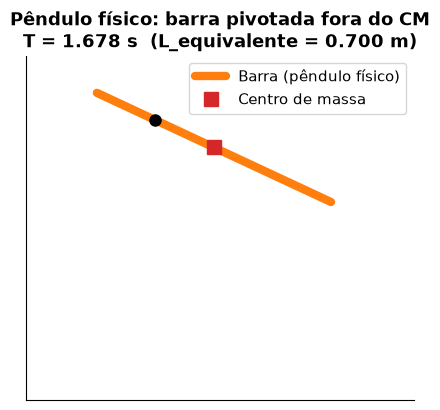

In [12]:
ell = 1.2  # comprimento da barra (m)
m_barra = 2.0  # kg
d_pivo = 0.3  # distância do pivô até a extremidade mais próxima (m)

# momento de inércia da barra em torno do CM: (1/12) m ell^2
I_cm = (1 / 12) * m_barra * ell**2
dist_cm_pivo = ell / 2 - d_pivo  # distância do CM ao pivô
I_pivo = I_cm + m_barra * dist_cm_pivo**2  # teorema dos eixos paralelos

k_giro = np.sqrt(I_pivo / m_barra)
T_fisico = 2 * np.pi * np.sqrt(I_pivo / (m_barra * g * dist_cm_pivo))

print(f"Momento de inércia no CM: I_cm = {I_cm:.4f} kg·m²")
print(f"Distância do pivô ao CM: d = {dist_cm_pivo:.3f} m")
print(f"Momento de inércia no pivô (eixos paralelos): I = {I_pivo:.4f} kg·m²")
print(f"Raio de giração: k_g = sqrt(I/m) = {k_giro:.4f} m")
print(f"Período do pêndulo físico: T = {T_fisico:.4f} s")

# comparação visual: pêndulo físico (barra) vs pêndulo simples equivalente
L_equivalente = I_pivo / (m_barra * dist_cm_pivo)
print(f"Comprimento do pêndulo simples equivalente: L_ef = I/(m d) = {L_equivalente:.4f} m")

fig, ax = plt.subplots(figsize=(5, 5.5))
ang0 = np.radians(25)
ax.plot([0, ell * np.sin(ang0) * (0 - d_pivo) / ell], [0, -(0 - d_pivo) * np.cos(ang0)], alpha=0)  # placeholder scale
# desenha a barra girada por ang0 em torno do pivô (no topo)
xs_barra = np.array([-d_pivo, ell - d_pivo])
ys_barra = np.array([0, 0])
xs_rot = xs_barra * np.cos(ang0) - ys_barra * np.sin(ang0)
ys_rot = -(xs_barra * np.sin(ang0) + ys_barra * np.cos(ang0))
ax.plot(xs_rot, ys_rot, color=COR_LARANJA, linewidth=6, solid_capstyle="round", label="Barra (pêndulo físico)")
ax.plot(0, 0, "ko", markersize=8, zorder=5)
x_cm = dist_cm_pivo * np.cos(ang0)
y_cm = -dist_cm_pivo * np.sin(ang0)
ax.plot(x_cm, y_cm, "s", color=COR_DESTAQUE, markersize=10, label="Centro de massa")
ax.set_xlim(-0.6, 1.2)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="upper right")
ax.set_title(f"Pêndulo físico: barra pivotada fora do CM\nT = {T_fisico:.3f} s  (L_equivalente = {L_equivalente:.3f} m)")
plt.show()


<a id="sec9"></a>
## 9. Oscilações de duas partículas

Quando duas massas $m_1$ e $m_2$ estão ligadas por uma mola (sem suporte externo), ambas oscilam — mas o **centro de massa permanece parado** (ou em movimento retilíneo uniforme, se já tivesse velocidade inicial). O problema de dois corpos se reduz a um problema de **um corpo equivalente**, com massa reduzida

$$\mu = \frac{m_1 m_2}{m_1+m_2}$$

que oscila com a mesma frequência que teria uma massa $\mu$ presa a uma mola fixa:

$$\omega = \sqrt{\frac{k}{\mu}}$$

Essa redução é exatamente o formalismo usado para descrever a **vibração de moléculas diatômicas** (ex. uma molécula de HCl): as duas massas são os átomos, a "mola" representa a ligação química, e $\mu$ é a massa reduzida do par atômico — o mesmo $\omega=\sqrt{k/\mu}$ aparece na espectroscopia vibracional.

> **Intuição física:** é como se o sistema "esquecesse" que são dois corpos e se comportasse como um único corpo de massa $\mu$ oscilando em relação ao CM fixo.

In [13]:
m1, m2, k9 = 1.0, 3.0, 5.0
mu = (m1 * m2) / (m1 + m2)
omega9 = np.sqrt(k9 / mu)

L0 = 2.0  # comprimento natural da mola
A9 = 0.5  # amplitude da coordenada relativa

t9 = np.linspace(0, 2 * 2 * np.pi / omega9, 160)
s9 = A9 * np.cos(omega9 * t9)  # deslocamento relativo (x2 - x1 - L0)

# posições em torno do CM fixo (CM na origem)
x1_t = -(m2 / (m1 + m2)) * (L0 + s9)
x2_t = (m1 / (m1 + m2)) * (L0 + s9)

fig, ax = plt.subplots(figsize=(9, 3))


def animar_duas_massas(i):
    ax.clear()
    xs_mola = np.linspace(x1_t[i], x2_t[i], 30)
    ys_mola = 0.1 * np.sign(np.sin(np.linspace(0, 13 * np.pi, 30)))
    ys_mola[0] = ys_mola[-1] = 0
    ax.plot(xs_mola, ys_mola, color="dimgray")
    ax.add_patch(Circle((x1_t[i], 0), 0.12, color=COR_AZUL, zorder=5))
    ax.add_patch(Circle((x2_t[i], 0), 0.12 * (m2 / m1) ** (1 / 3), color=COR_DESTAQUE, zorder=5))
    ax.axvline(0, color="black", linestyle=":", linewidth=1)
    ax.text(0, 0.35, "CM (parado)", ha="center", fontsize=9)
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_title(f"Duas massas ligadas por mola: m1={m1} kg (azul), m2={m2} kg (vermelho) — μ = {mu:.2f} kg")
    return []


anim9 = animation.FuncAnimation(fig, animar_duas_massas, frames=len(t9), interval=50, blit=False)
plt.close(fig)
HTML(anim9.to_jshtml())


<a id="sec10"></a>
## 10. MHS como projeção de um MCU

Uma forma elegante de enxergar o MHS: imagine uma partícula em **Movimento Circular Uniforme (MCU)** de raio $A$ e velocidade angular $\omega$. Sua posição é $(A\cos\theta, A\sin\theta)$ com $\theta=\omega t+\phi$. A **projeção no eixo x** dessa partícula é

$$x(t) = A\cos(\omega t+\phi)$$

— exatamente a solução do MHS! Essa equivalência geométrica é extremamente útil: tudo que sabemos sobre MCU (velocidade angular, período) se traduz diretamente para o MHS.

In [14]:
A10, omega10 = 1.0, 2.0
t10 = np.linspace(0, 2 * np.pi / omega10, 120)
theta10 = omega10 * t10
x10 = A10 * np.cos(theta10)
y10 = A10 * np.sin(theta10)

fig, (ax_circ, ax_proj) = plt.subplots(1, 2, figsize=(11, 4.5))

circ = plt.Circle((0, 0), A10, fill=False, color="lightgray")
ax_circ.add_patch(circ)
ponto_mcu, = ax_circ.plot([], [], "o", color=COR_DESTAQUE, markersize=10)
raio_linha, = ax_circ.plot([], [], color=COR_DESTAQUE, linewidth=1.5)
linha_proj, = ax_circ.plot([], [], color="gray", linestyle=":", linewidth=1.2)
ax_circ.set_xlim(-1.3, 1.3)
ax_circ.set_ylim(-1.3, 1.3)
ax_circ.set_aspect("equal")
ax_circ.set_title("MCU: partícula girando")
ax_circ.axhline(0, color="black", linewidth=0.6)
ax_circ.axvline(0, color="black", linewidth=0.6)

ax_proj.plot(t10, x10, color="lightgray", linewidth=1.2)
linha_xt, = ax_proj.plot([], [], color=COR_AZUL, linewidth=2.3)
ponto_proj, = ax_proj.plot([], [], "o", color=COR_AZUL, markersize=8)
ax_proj.set_xlim(t10[0], t10[-1])
ax_proj.set_ylim(-1.3, 1.3)
ax_proj.set_xlabel("t (s)")
ax_proj.set_title("x(t) = projeção no eixo x")

fig.tight_layout()


def animar_mcu(i):
    ponto_mcu.set_data([x10[i]], [y10[i]])
    raio_linha.set_data([0, x10[i]], [0, y10[i]])
    linha_proj.set_data([x10[i], x10[i]], [0, y10[i]])
    linha_xt.set_data(t10[: i + 1], x10[: i + 1])
    ponto_proj.set_data([t10[i]], [x10[i]])
    return [ponto_mcu, raio_linha, linha_proj, linha_xt, ponto_proj]


anim10 = animation.FuncAnimation(fig, animar_mcu, frames=len(t10), interval=50, blit=False)
plt.close(fig)
HTML(anim10.to_jshtml())


<a id="sec11"></a>
## 11. Notação complexa para o MHS (fórmula de Euler)

A fórmula de Euler conecta exponenciais complexas com funções trigonométricas:

$$e^{i\theta} = \cos\theta + i\sin\theta$$

Isso permite escrever o MHS de forma compacta usando um número complexo (ou **fasor**) girante:

$$z(t) = Ae^{i(\omega t+\phi)}, \qquad x(t) = \text{Re}[z(t)] = A\cos(\omega t+\phi)$$

Geometricamente, isso é **exatamente** a mesma ideia da Seção 10: o fasor $z(t)$ gira no plano complexo com velocidade angular $\omega$, e sua parte real é a projeção no eixo real — que é o MHS. A notação complexa é extremamente útil em circuitos AC e óptica, pois simplifica contas de soma de ondas (que viram soma de exponenciais complexas).

> **Dica de prova:** derivar $z(t)=Ae^{i\omega t}$ em relação a $t$ é só multiplicar por $i\omega$ — por isso a notação complexa simplifica tanto derivadas quanto integrais de funções senoidais.

In [15]:
A11, omega11, phi11 = 1.0, 2.0, np.radians(30)
t11 = np.linspace(0, 2 * np.pi / omega11, 120)
z11 = A11 * np.exp(1j * (omega11 * t11 + phi11))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
circ11 = plt.Circle((0, 0), A11, fill=False, color="lightgray")
ax.add_patch(circ11)
fasor, = ax.plot([], [], color=COR_ROXO, linewidth=2)
ponta_fasor, = ax.plot([], [], "o", color=COR_ROXO, markersize=9)
proj_linha, = ax.plot([], [], color="gray", linestyle=":", linewidth=1.2)
proj_ponto, = ax.plot([], [], "o", color=COR_AZUL, markersize=9)

ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.set_xlabel("Re(z) = x(t)")
ax.set_ylabel("Im(z)")
ax.set_title(r"Fasor $z(t)=Ae^{i(\omega t+\phi)}$ e sua projeção real = x(t)")


def animar_fasor(i):
    re, im = z11[i].real, z11[i].imag
    fasor.set_data([0, re], [0, im])
    ponta_fasor.set_data([re], [im])
    proj_linha.set_data([re, re], [0, im])
    proj_ponto.set_data([re], [0])
    return [fasor, ponta_fasor, proj_linha, proj_ponto]


anim11 = animation.FuncAnimation(fig, animar_fasor, frames=len(t11), interval=50, blit=False)
plt.close(fig)
HTML(anim11.to_jshtml())


---

## Resumo rápido

| Conceito | Fórmula-chave |
|---|---|
| Período / frequência | $f = 1/T,\; \omega = 2\pi f$ |
| Lei de Hooke | $F = -kx$ |
| Energia potencial harmônica | $U = \tfrac12 kx^2$ |
| EDO do MHS | $\ddot x + \omega^2 x = 0$ |
| Solução geral | $x(t) = A\cos(\omega t+\phi)$ |
| Energia total | $E = \tfrac12 kA^2$ (constante) |
| Pêndulo simples (pequenas oscilações) | $T = 2\pi\sqrt{L/g}$ |
| Pêndulo físico | $T = 2\pi\sqrt{I/(mgd)}$ |
| Pêndulo de torção | $T = 2\pi\sqrt{I/\kappa}$ |
| Massa reduzida | $\mu = m_1m_2/(m_1+m_2)$ |
| Notação complexa | $x(t) = \text{Re}[Ae^{i(\omega t+\phi)}]$ |

> Bom estudo! Lembre-se: o MHS está em toda parte porque **qualquer** sistema estável, perto do equilíbrio, oscila assim.